# Telco Customer Churn Binary Classification Model - by Umut Türkmen

## 1. Definition of The Problem


This notebook walks through the process of building an AI binary classification model model trained on the IBM Telco Customer Churn dataset. The objective is to predict whether customers will remain with the telecommunications company or leave (churn), based on data such as their tenure, contract type, and the type of internet service they use.



### About The Dataset




### Data Dictionary
This dataset consists of 21 features reflecting a telecommunications company's customer profile, subscribed services, account information, and whether they have left the company (Churn).

**1. Demographic Features**
* **customerID:** A random and unique identification number assigned to each customer (Text).
* **gender:** The gender of the customer (`Female`, `Male`).
* **SeniorCitizen:** Indicates whether the customer is 65 years or older (`0`: No, `1`: Yes).
* **Partner:** Indicates whether the customer has a partner/spouse (`Yes`, `No`).
* **Dependents:** Indicates whether the customer has dependents, such as children or elders (`Yes`, `No`).

**2. Account and Contract Information**
* **tenure:** The total number of months the customer has stayed with the company (Numeric, `0-72`).
* **Contract:** The contract term of the customer (`Month-to-month`, `One year`, `Two year`).
* **PaperlessBilling:** Indicates whether the customer uses paperless (digital/electronic) billing (`Yes`, `No`).
* **PaymentMethod:** The customer's payment method (`Electronic check`, `Mailed check`, `Bank transfer (automatic)`, `Credit card (automatic)`).
* **MonthlyCharges:** The current amount charged to the customer monthly (Numeric).
* **TotalCharges:** The total amount charged to the customer over their entire tenure (Numeric).

**3. Subscriptions and Service Details**
* **PhoneService:** Indicates whether the customer has a phone service (`No`, `Yes`).
* **MultipleLines:** Indicates whether the customer has multiple phone lines (`No phone service`, `No`, `Yes`).
* **InternetService:** The type of internet infrastructure the customer has (`DSL`, `Fiber optic`, `No`).
* **OnlineSecurity:** Indicates whether the customer has an online network security add-on (`No`, `Yes`, `No internet service`).
* **OnlineBackup:** Indicates whether the customer has an online backup service (`Yes`, `No`, `No internet service`).
* **DeviceProtection:** Indicates whether the customer has an equipment/device protection plan (`No`, `Yes`, `No internet service`).
* **TechSupport:** Indicates whether the customer has premium technical support (`No`, `Yes`, `No internet service`).
* **StreamingTV:** Indicates whether the customer uses the company's internet to stream TV (`No`, `Yes`, `No internet service`).
* **StreamingMovies:** Indicates whether the customer uses the company's internet to stream movies (`No`, `Yes`, `No internet service`).

**4. Target Variable**
* **Churn:** Indicates whether the customer has left the company / canceled their subscription (`No`: Stayed, `Yes`: Left). This is the main prediction target of our project.

## 2. Importing Libraries

In [3]:
import pandas as pd # DataFrame processes, CSV reading, Data Cleaning
import numpy as np # Array operations, mathematical controls
import matplotlib.pyplot as plt # Plotting graphics
from sklearn.model_selection import train_test_split # Splitting the data into training and testing sets
from sklearn.tree import DecisionTreeClassifier, plot_tree # DecisionTree model to classify data and visualizing how the decision tree branches out
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix # Reporting the results comprehensively

## 3. Preparing and Cleaning The Data

In [4]:
df = pd.read_csv('IBM-Telco-Customer-Churn.csv')

In [5]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
df.shape

(7043, 21)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [8]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


As you can see from the analysis, our dataset contains only three `int64` columns. Furthermore, the 'TotalCharges' column—which should have been numerical—is currently stored as an `object` (string) type. **So, it turns out we have some hidden characters that cannot be converted into numbers.** We also have binary columns containing 'yes/no' values. In the subsequent steps, we will process these and convert them into numerical values, enabling us to perform mathematical operations on them.

In [9]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [10]:
df[df['tenure'] == 0]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [11]:
print(repr(df[df['tenure'] == 0].head(1)['TotalCharges'].iloc[0]))
print(type(df[df['tenure'] == 0].head(1)['TotalCharges'].iloc[0]))

' '
<class 'str'>


As can be seen here, customers with a tenure value of 0 also have a TotalCharges value of 0. However, for 11 customers, this value was entered as ' ' (an empty string) instead of 0, which has caused this column to have a string data type. We will clean the data by updating these empty values ​to NaN first, then convert NaN's to 0.

In [12]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [13]:
df['TotalCharges'].isnull().sum()

np.int64(11)

In [14]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df['TotalCharges'].dtype

dtype('float64')

Since 'customerID' is not related to our target variable, we can remove it.

In [15]:
df = df.drop(columns='customerID', errors='ignore') #Since I ran it multiple times, it would throw an error after the first run because it couldn't find the column; therefore, errors have been ignored.
df.head(2)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No


## 4.Exploratory Data Analysis (EDA) and Visualization

In [16]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [17]:
df['Churn'].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

Approximately 73.5% of the customers in the data have remained, while 26.5% have left. In data science, this is referred to as an **Imbalanced Dataset**.

In [18]:
df.groupby('Churn')[['tenure', 'MonthlyCharges', 'TotalCharges']].mean()

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.569965,61.265124,2549.911442
Yes,17.979133,74.441332,1531.796094


Customers who remain have higher tenure, lower monthly payments, and higher total payments. For customers who have left, the situation is the exact opposite. This indicates that these values ​​have a significant impact on our target variable.

In [19]:
df.groupby('Contract')['Churn'].value_counts(normalize=True) * 100

Contract        Churn
Month-to-month  No       57.290323
                Yes      42.709677
One year        No       88.730482
                Yes      11.269518
Two year        No       97.168142
                Yes       2.831858
Name: proportion, dtype: float64

In [20]:
df.groupby('gender')['Churn'].value_counts(normalize=True) * 100

gender  Churn
Female  No       73.079128
        Yes      26.920872
Male    No       73.839662
        Yes      26.160338
Name: proportion, dtype: float64

Observe that for the 'Contract' type, the churn rate drops from 42% to 2.8%, while there is no difference between genders—26.9% for women versus 26.1% for men. This means that while some parameters have a significant impact on the target variable, there are also irrelevant variables. For the sake of simplicity, we can remove these irrelevant variables in the subsequent stages.

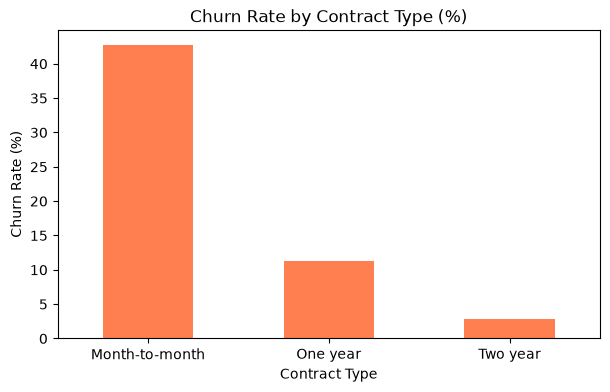

In [21]:
contract_churn = pd.crosstab(df['Contract'], df['Churn'], normalize='index')['Yes'] * 100
contract_churn.plot(kind='bar',color='coral', figsize=(7, 4))
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')
plt.title('Churn Rate by Contract Type (%)')
plt.xticks(rotation=0)
plt.show()

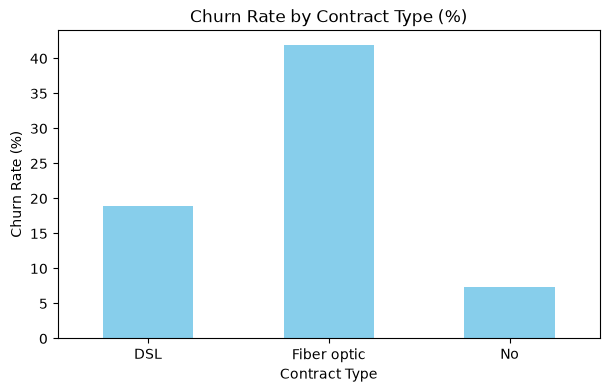

In [22]:
contract_churn = pd.crosstab(df['InternetService'], df['Churn'], normalize='index')['Yes'] * 100
contract_churn.plot(kind='bar',color='skyblue', figsize=(7, 4))
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')
plt.title('Churn Rate by Contract Type (%)')
plt.xticks(rotation=0)
plt.show()

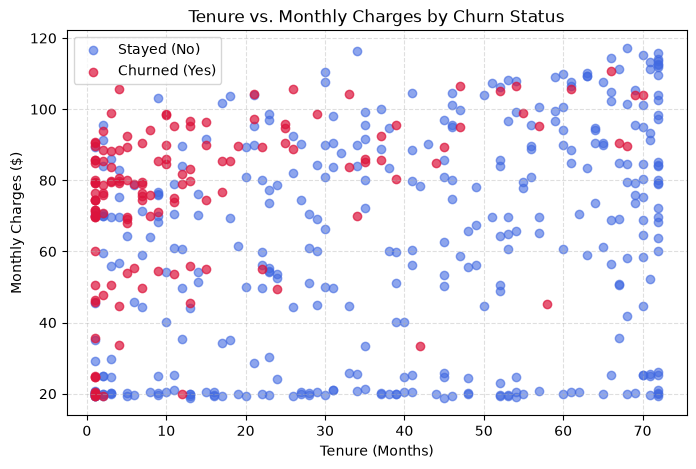

In [23]:
sample_df = df.sample(n=500, random_state=42)
churn_no = sample_df[sample_df['Churn'] == 'No']
churn_yes = sample_df[sample_df['Churn'] == 'Yes']

plt.figure(figsize=(8, 5))
plt.scatter(churn_no['tenure'], churn_no['MonthlyCharges'], color='royalblue', alpha=0.6, label='Stayed (No)')
plt.scatter(churn_yes['tenure'], churn_yes['MonthlyCharges'], color='crimson', alpha=0.7, label='Churned (Yes)')

plt.title('Tenure vs. Monthly Charges by Churn Status')
plt.xlabel('Tenure (Months)')
plt.ylabel('Monthly Charges ($)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

**Discovery Findings: A list of observations after EDA (which characteristic is the defining one?)**


*   *Contract & Internet Service impact:* Customers with a month-to-month contract who use fiber-optic internet exhibit a significantly higher churn rate.

*   *Interaction between Tenure and Monthly Charges (Scatter Plot interpretation):* Customers with a tenure of up to 20 months who pay more than $70 per month constitute the highest-risk group.

*   *Non-influential variables:* certain demographic characteristics, such as gender, do not create a significant difference in terms of customer churn.








## 5.Building and Training The Model

### Feature Selection and Encoding

To prevent the model from overfitting and to avoid including an excessive number of parameters in the intelligent prediction tool, we will remove values ​​that have virtually no impact on the data. If we keep all 19 features, we would have to enter 19 inputs on the screen when testing the mini-application.

So, we continue with features "tenure, MonthlyCharges, TotalCharges, Contract, InternetService, TechSupport, OnlineSecurity, SeniorCitizen" and target variable "Churn".

In [24]:
model_df = df[['tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'InternetService', 'TechSupport', 'OnlineSecurity', 'SeniorCitizen', 'Churn']].copy()

model_df['Churn'] = model_df['Churn'].map({'No': 0, 'Yes': 1})
model_df['Contract'] = model_df['Contract'].map({'Month-to-month': 0, 'One year': 1, 'Two year': 2})
model_df['InternetService'] = model_df['InternetService'].map({'No': 0, 'DSL': 1, 'Fiber optic': 2})
model_df['TechSupport'] = model_df['TechSupport'].map({'No': 0, 'No internet service': 0, 'Yes': 1})
model_df['OnlineSecurity'] = model_df['OnlineSecurity'].map({'No': 0, 'No internet service': 0, 'Yes': 1})

model_df.head()

,tenure,MonthlyCharges,TotalCharges,Contract,InternetService,TechSupport,OnlineSecurity,SeniorCitizen,Churn
0,1,29.85,29.85,0,1,0,0,0,0
1,34,56.95,1889.50,1,1,0,1,0,0
2,2,53.85,108.15,0,1,0,1,0,1
3,45,42.30,1840.75,1,1,1,1,0,0
4,2,70.70,151.65,0,2,0,0,0,1


In [25]:
model_df.isnull().sum()

tenure             0
MonthlyCharges     0
TotalCharges       0
Contract           0
InternetService    0
TechSupport        0
OnlineSecurity     0
SeniorCitizen      0
Churn              0
dtype: int64

### Splitting Data and Training the Model

In [26]:
X = model_df.drop(columns='Churn')
y = model_df['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(5634, 8)
(1409, 8)
(5634,)
(1409,)


We allocated 80% of the data for training and 20% for testing (this is the industry standard).

In [27]:
model = DecisionTreeClassifier(max_depth=4, random_state=42)
model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

We selected Decision Trees as our model. Decision Trees are the most suitable choice for our objectives and data, as they can naturally handle both numerical and categorical data, capture non-linear customer behaviors through "if-then" rules, and function as an explainable, "white-box" model that can be easily visualized.

We chose 4 for the `max_depth` parameter because we do not want the model to overfit the data. This ensures that, when asking "if-then" questions along the branches of the tree, the model will not go too deep and will instead learn general rules.

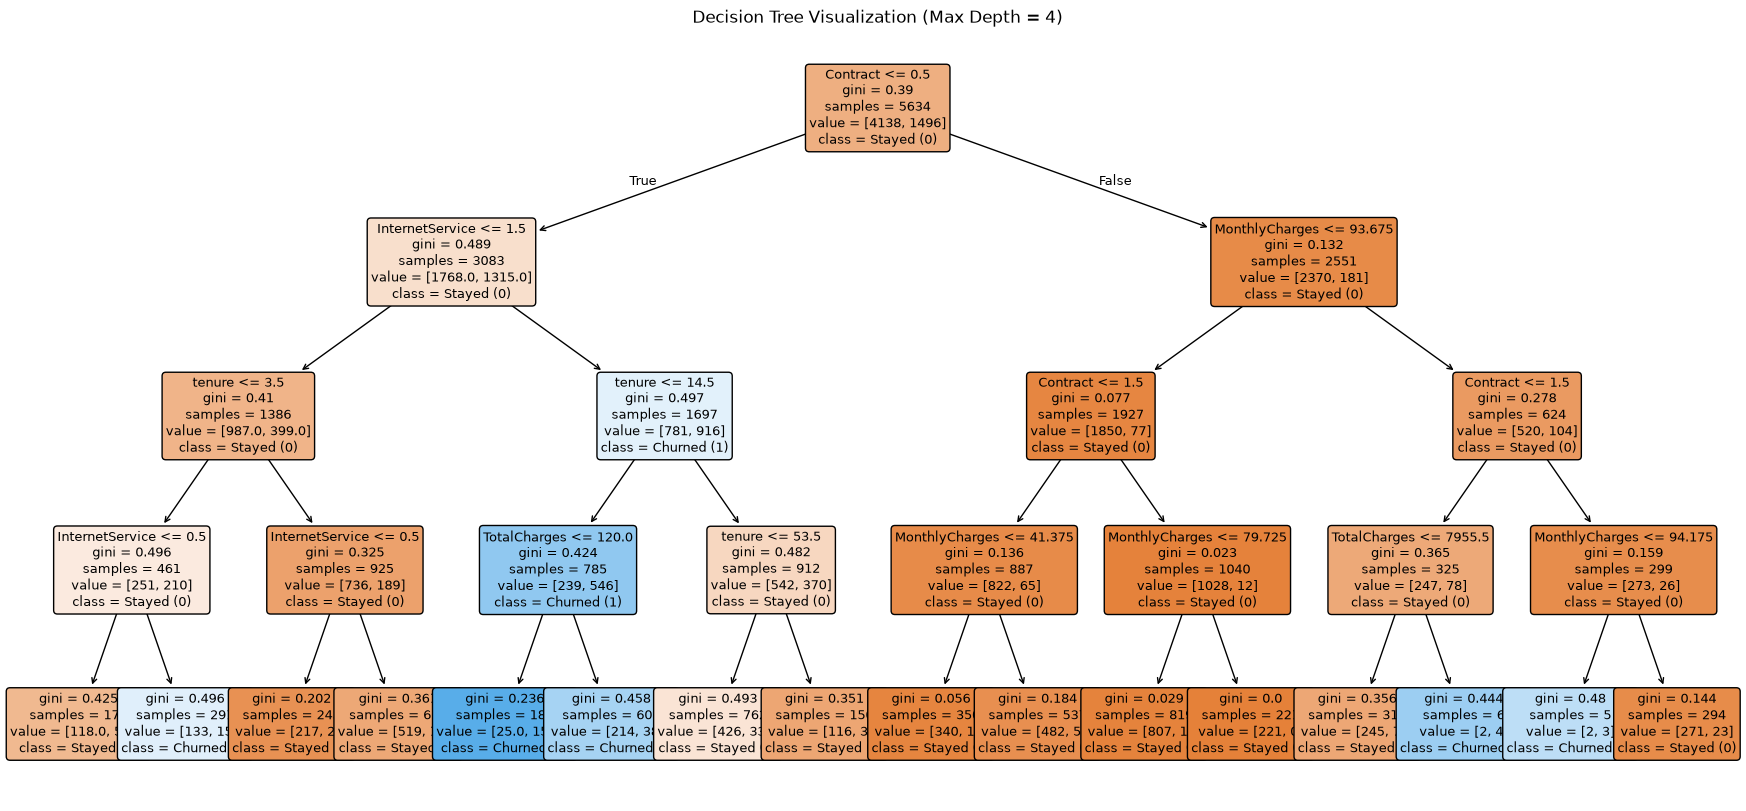

In [28]:
plt.figure(figsize=(22,10))
plot_tree(model, feature_names=X.columns, class_names=['Stayed (0)', 'Churned (1)'], filled=True, rounded=True, fontsize=9)
plt.title('Decision Tree Visualization (Max Depth = 4)')
plt.show()


At the bottom right of the tree, there are two blue (Churned) leaf nodes containing only 5 and 6 samples. This happens because the algorithm creates overly specific rules for a tiny group of high-paying customers (MonthlyCharges > 93.675) to minimize Gini impurity. Since leaves with such small sample sizes are not statistically reliable, we will address this limitation and how to fix it in the Model Evaluation section.

## 6.Prediction and Evaluation

In [29]:
y_pred = model.predict(X_test)
test_success = accuracy_score(y_test, y_pred)
train_success = accuracy_score(y_train, model.predict(X_train))
print(f'Test Success Rate: {test_success * 100:.2f}%')
print(f'Train Success Rate: {train_success * 100:.2f}%')

Test Success Rate: 79.70%
Train Success Rate: 79.39%


Our training accuracy (79.39%) and test accuracy (79.70%) are nearly identical! This indicates that our `max_depth=4` constraint worked exceptionally well; there is absolutely no overfitting in our model—instead of simply memorizing the data, the model has learned general rules.

In [30]:
new_customers = pd.DataFrame({'tenure': [2, 48, 12], 'MonthlyCharges': [85.0, 50.0, 75.0], 'TotalCharges': [170.0, 2400.0, 900.0], 'Contract': [0, 2, 0], 'InternetService': [2, 1, 2], 'TechSupport': [0, 1, 0], 'OnlineSecurity': [0, 1, 0], 'SeniorCitizen': [1, 0, 0]})
new_customers['Predicted Churn'] = model.predict(new_customers)
new_customers

,tenure,MonthlyCharges,TotalCharges,Contract,InternetService,TechSupport,OnlineSecurity,SeniorCitizen,Predicted Churn
0,2,85.0,170.0,0,2,0,0,1,1
1,48,50.0,2400.0,2,1,1,1,0,0
2,12,75.0,900.0,0,2,0,0,0,1


The model has accurately classified new data, correctly identifying fiber internet users with monthly contracts and high bills (Customers 1 and 3) as "Churn (1)," while classifying the customer with a long-term contract (Customer 2) as "Staying (0)."

### Weaknesses of the Model and Potential Improvements

In [31]:
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[941  95]
 [191 182]]
              precision    recall  f1-score   support

           0       0.83      0.91      0.87      1036
           1       0.66      0.49      0.56       373

    accuracy                           0.80      1409
   macro avg       0.74      0.70      0.71      1409
weighted avg       0.79      0.80      0.79      1409



Since the proportion of customers who remained (73.5%) in our dataset is significantly higher than those who left (26.5%), our model performs very well in predicting "those who stayed (0)" (Recall = 0.91), but struggles to identify "those who left (1)"—our primary target (Recall = 0.49, with 191 customers missed). For a telecommunications company, failing to identify a customer who is about to leave (a False Negative) is far more costly than mistakenly offering a discount to a customer who would have stayed anyway (a False Positive).

**Future Improvements**


*   *Class Weighting (class_weight='balanced'):* We can increase the recall rate by instructing the decision tree to assign a higher penalty for missing customers (1).
*   *Ensemble Methods:* Instead of relying on a single Decision Tree, we can switch to algorithms like Random Forest or Gradient Boosting (XGBoost)—where hundreds of trees reach a collective decision—to both prevent the errors associated with small, 5–6-person leaf nodes and improve overall performance.

## 7.Smart Prediction Function

In [32]:
def predict_churn(tenure, monthly_charges, total_charges, contract, internet_service, tech_support, online_security, senior_citizen):
    new_customer = pd.DataFrame({'tenure': [tenure], 'MonthlyCharges': [monthly_charges], 'TotalCharges': [total_charges], 'Contract': [contract], 'InternetService': [internet_service], 'TechSupport': [tech_support], 'OnlineSecurity': [online_security], 'SeniorCitizen': [senior_citizen]})
    prediction = model.predict(new_customer)[0]
    prediction_prob = model.predict_proba(new_customer)[0][1] * 100
    if prediction == 1:
      return f'There is a {prediction_prob:.2f}% probability that the customer belongs to the churn group. The company needs to urgently offer a commitment/discount campaign to this customer.'
    else:
      return f'There is a {(100-prediction_prob):.2f}% probability that the customer will remain. The company must maintain its current level of service quality.'

In [34]:
tenure = int(input('Enter tenure: '))
monthly_charges = float(input('Enter monthly charges ($): '))
total_charges = float(input('Enter total charges ($): '))
contract = int(input('Enter contract (Month-to-month = 0, One year = 1, Two year = 2): '))
internet_service = int(input('Enter internet service (No = 0, DSL = 1, Fiber optic = 2): '))
tech_support = int(input('Enter tech support (No = 0, No internet service = 0, Yes = 1): '))
online_security = int(input('Enter online security (No = 0, No internet service = 0, Yes = 1): '))
senior_citizen = int(input('Enter senior citizen (No = 0, Yes = 1): '))

print(predict_churn(tenure, monthly_charges, total_charges, contract, internet_service, tech_support, online_security, senior_citizen))

There is a 64.45% probability that the customer belongs to the churn group. The company needs to urgently offer a commitment/discount campaign to this customer.


This end-to-end machine learning project successfully addresses a critical telecommunications challenge—customer churn prediction—using the IBM Telco dataset. By combining thorough exploratory data analysis, a transparent decision tree model, and an interactive prediction tool, this work demonstrates both technical proficiency and business intelligence. It serves as a solid foundation for proactive customer retention strategies and stands as a robust portfolio piece for future data science applications.